# 01 · Data and labels: what can we trust before modelling?

The task is to group telecom network alarms into **incidents**, so that one outage raises one ticket instead of dozens.
There is no ground-truth incident label in production. Before building any model, this notebook asks:

1. What does the operator actually observe, and where is it incomplete?
2. Which signals could stand in for a label (**tickets**, **clear times**, **resolution codes**), and how does each one fail?

The data comes from [`synthetic/generate.py`](../synthetic/generate.py), a simulator that reproduces the failure modes found in a real network
operations dataset. Because it is synthetic, we also have the **ground truth** (`truth/`). We use it here *only* to measure how good each
candidate label is. No model in this project ever sees it as an input.

In [1]:
import sys, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = Path.cwd().parent
DATA = ROOT / "data" / "synthetic"
sys.path.insert(0, str(ROOT / "synthetic"))
from generate import RESOLUTION

if not (DATA / "alarms.csv").exists():
    subprocess.run([sys.executable, str(ROOT / "synthetic" / "generate.py"), "--days", "14", "--out", str(DATA)], check=True)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e8e7e3"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6, "axes.axisbelow": True,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "lines.linewidth": 2, "legend.frameon": False,
})

alarms = pd.read_csv(DATA / "alarms.csv", parse_dates=["onset_time", "clear_time"])
tickets = pd.read_csv(DATA / "tickets.csv", parse_dates=["open_time", "restore_time", "close_time"])
ticket_alarms = pd.read_csv(DATA / "ticket_alarms.csv")
sites = pd.read_csv(DATA / "inventory" / "sites.csv")
links = pd.read_csv(DATA / "inventory" / "links.csv")
truth = pd.read_csv(DATA / "truth" / "alarms.csv", parse_dates=["true_clear_time"])
incidents = pd.read_csv(DATA / "truth" / "incidents.csv", parse_dates=["start_time", "end_time"])

span = alarms.onset_time.max() - alarms.onset_time.min()
print(f"{len(alarms):,} alarms over {span / pd.Timedelta('1D'):.0f} days, {len(tickets):,} tickets, "
      f"{(sites.kind == 'site').sum()} sites, {len(incidents):,} true incidents")

39,030 alarms over 14 days, 2,548 tickets, 240 sites, 20,874 true incidents


## 1 · What the operator sees

Alarms arrive as a steady background of minor events, with bursts when something big fails.

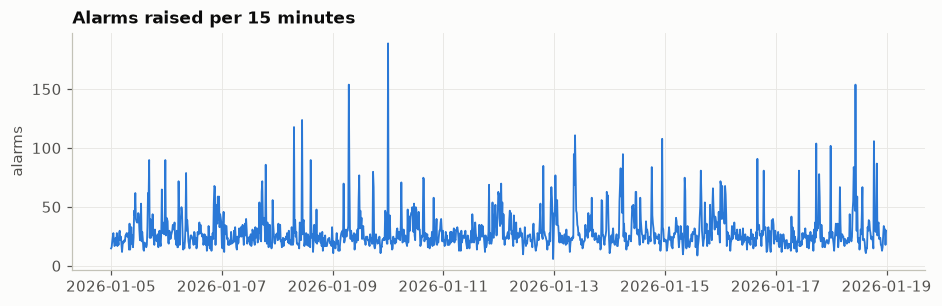

severity,critical,major,minor,warning,total
domain,,,,,
environment,0,0,5075,4807,9882
power,388,667,4846,0,5901
ran,707,6292,6168,0,13167
transport,32,295,9753,0,10080
total,1127,7254,25842,4807,39030


In [2]:
per_15 = alarms.set_index("onset_time").resample("15min").size()
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(per_15.index, per_15.values, color=BLUE, lw=1.2)
ax.set_title("Alarms raised per 15 minutes")
ax.set_ylabel("alarms")
plt.show()

pd.crosstab(alarms.domain, alarms.severity, margins=True, margins_name="total")

## 2 · Gap one: alarms with no place in the topology

Some network elements are missing from the inventory. Their alarms carry only a legacy node alias, so we can't attach them to a site or
to the topology graph. A purely topological model would silently drop them.

Overall: 31% of alarms cannot be placed on a site.


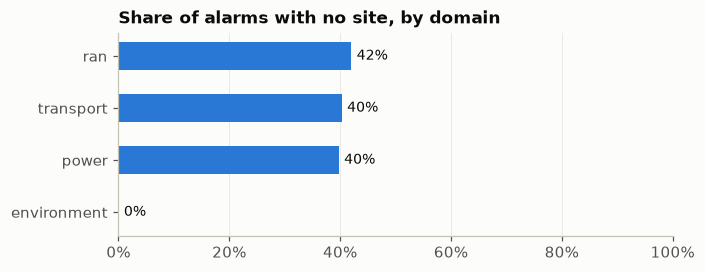

In [3]:
no_site = alarms.site_id.isna().groupby(alarms.domain).mean().sort_values()
fig, ax = plt.subplots(figsize=(6.5, 2.4))
ax.barh(no_site.index, no_site.values, color=BLUE, height=.55)
for y, v in enumerate(no_site.values):
    ax.text(v + .01, y, f"{v:.0%}", va="center", color=INK, fontsize=9)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Share of alarms with no site, by domain")
ax.grid(axis="y", visible=False)
plt.show()

print(f"Overall: {alarms.site_id.isna().mean():.0%} of alarms cannot be placed on a site.")

## 3 · What an incident really looks like (ground truth, synthetic only)

Most incidents are a single minor alarm of background noise. Among real faults, a few large events (area power outages, fibre cuts,
neighbour-link storms) produce most of the alarm volume. The heavy tail matters: a grouping method that is right on the many small incidents can still be wrong on most alarms.

Background noise: 98% of incidents, 76% of alarms, at most 6.0 alarms each (flapping).


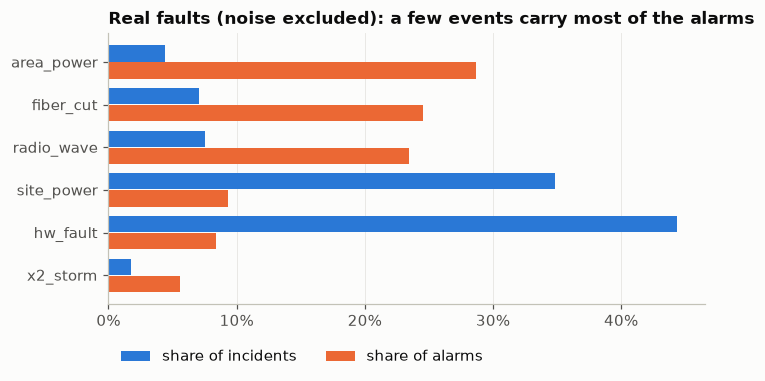

,incidents,alarms,median_alarms,max_alarms,max_sites
kind,,,,,
noise,20423,29486,1.0,6,1
area_power,20,2740,117.0,305,41
fiber_cut,32,2344,72.0,139,28
radio_wave,34,2235,67.0,110,25
site_power,157,890,1.0,48,9
hw_fault,200,801,4.0,9,1
x2_storm,8,534,74.0,99,99


In [4]:
by_kind = incidents.groupby("kind").agg(
    incidents=("incident_id", "size"), alarms=("n_alarms", "sum"),
    median_alarms=("n_alarms", "median"), max_alarms=("n_alarms", "max"), max_sites=("n_sites", "max"))
noise = by_kind.loc["noise"]
print(f"Background noise: {noise.incidents / by_kind.incidents.sum():.0%} of incidents, "
      f"{noise.alarms / by_kind.alarms.sum():.0%} of alarms, at most {noise.max_alarms} alarms each (flapping).")
faults = by_kind.drop("noise")
share = pd.DataFrame({"share of incidents": faults.incidents / faults.incidents.sum(),
                      "share of alarms": faults.alarms / faults.alarms.sum()}).sort_values("share of alarms")

fig, ax = plt.subplots(figsize=(7, 3.2))
y = np.arange(len(share))
ax.barh(y + .2, share["share of incidents"], height=.38, color=BLUE, label="share of incidents")
ax.barh(y - .2, share["share of alarms"], height=.38, color=ORANGE, label="share of alarms")
ax.set_yticks(y, share.index)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("Real faults (noise excluded): a few events carry most of the alarms")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(0, -.12), ncol=2)
plt.show()

by_kind.sort_values("alarms", ascending=False)

## 4 · Candidate label A: tickets

The ticketing system opens one ticket per site when a major alarm arrives, and attaches the alarms that fire close to it.
Three things go wrong with tickets as labels:

* **recall**: alarms that fire later, or only at a neighbouring site, never reach a ticket;
* **fragmentation**: a multi-site incident becomes many tickets, one per site;
* **duplicates**: the same fault reopened later gets a fresh ticket, and only a few are marked as duplicates.

Alarms of ticketed incidents that sit on a ticket: 75%
Of the missed ones: 83% fired more than 15 min after the incident began, 26% are minor or warning


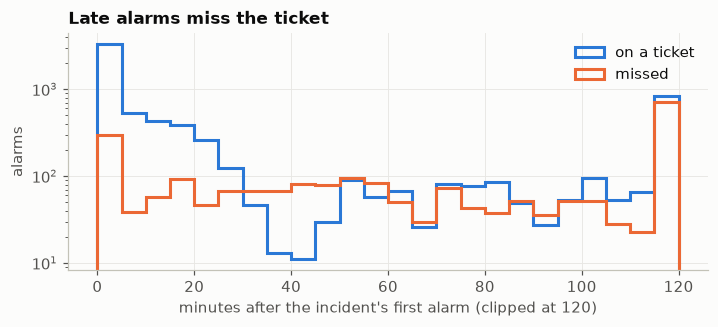

In [5]:
a = alarms.merge(truth, on="alarm_id")
a["on_ticket"] = a.alarm_id.isin(ticket_alarms.alarm_id)
ticketed = a[a.incident_id.isin(a.loc[a.on_ticket, "incident_id"])].copy()
ticketed["min_after_start"] = (ticketed.onset_time
                               - ticketed.groupby("incident_id").onset_time.transform("min")).dt.total_seconds() / 60

recall = ticketed.on_ticket.mean()
missed = ticketed[~ticketed.on_ticket]
print(f"Alarms of ticketed incidents that sit on a ticket: {recall:.0%}")
print(f"Of the missed ones: {(missed.min_after_start > 15).mean():.0%} fired more than 15 min after the incident began, "
      f"{(missed.severity.isin(['minor', 'warning'])).mean():.0%} are minor or warning")

bins = np.arange(0, 125, 5)
fig, ax = plt.subplots(figsize=(7.5, 2.8))
for flag, colour, label in [(True, BLUE, "on a ticket"), (False, ORANGE, "missed")]:
    v = ticketed.loc[ticketed.on_ticket == flag, "min_after_start"].clip(upper=120)
    ax.hist(v, bins=bins, histtype="step", lw=2, color=colour, label=label)
ax.set_yscale("log")
ax.set_xlabel("minutes after the incident's first alarm (clipped at 120)")
ax.set_ylabel("alarms")
ax.set_title("Late alarms miss the ticket")
ax.legend()
plt.show()

Tickets whose alarms all belong to one incident: 97%
Multi-site incidents: median 11 tickets each, up to 86. Merging these tickets back together is the business problem.


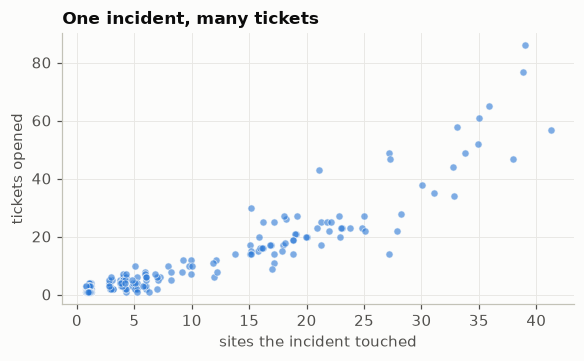

In [6]:
tk = ticket_alarms.merge(truth[["alarm_id", "incident_id"]], on="alarm_id")
dominant = tk.groupby("ticket_id").incident_id.agg(lambda s: s.value_counts().index[0])
pure = (tk.incident_id == tk.ticket_id.map(dominant)).groupby(tk.ticket_id).all()
print(f"Tickets whose alarms all belong to one incident: {pure.mean():.0%}")

per_inc = incidents.set_index("incident_id").join(dominant.value_counts().rename("n_tickets"), how="inner")
fig, ax = plt.subplots(figsize=(6, 3.2))
jitter = np.random.default_rng(0).uniform(-.25, .25, len(per_inc))
ax.scatter(per_inc.n_sites + jitter, per_inc.n_tickets, s=22, color=BLUE, alpha=.6, edgecolor="#fcfcfb", lw=.6)
ax.set_xlabel("sites the incident touched")
ax.set_ylabel("tickets opened")
ax.set_title("One incident, many tickets")
plt.show()

multi = per_inc[per_inc.n_sites > 1]
print(f"Multi-site incidents: median {multi.n_tickets.median():.0f} tickets each, up to {multi.n_tickets.max():.0f}. "
      "Merging these tickets back together is the business problem.")

In [7]:
t = tickets.copy()
t["key"] = t.site_id.fillna(t.node_alias)
t["incident_id"] = t.ticket_id.map(dominant)
recurrence_of = incidents.set_index("incident_id").recurrence_of
t["family"] = [r if pd.notna(r) else i for i, r in zip(t.incident_id, t.incident_id.map(recurrence_of))]
t = t.sort_values("open_time")
t["is_repeat"] = t.duplicated(["key", "family"])
t["marked_duplicate"] = t.resolution_note.eq("DUPLICATE JOB")

print(f"Tickets that repeat an earlier ticket on the same fault: {t.is_repeat.sum()} "
      f"({t.is_repeat.mean():.0%} of all tickets)")
print(f"... of which a person marked DUPLICATE JOB: {t.loc[t.is_repeat, 'marked_duplicate'].mean():.0%}")
pd.crosstab(t.is_repeat, t.marked_duplicate)

Tickets that repeat an earlier ticket on the same fault: 511 (20% of all tickets)
... of which a person marked DUPLICATE JOB: 21%


marked_duplicate,False,True
is_repeat,,
False,2026,11
True,405,106


## 5 · Candidate label B: clear times

A natural idea: *alarms that clear together were caused by the same thing*. Two problems:

* some clear times are not real. They were **bulk-stamped** from the ticket's close time, which lags the real restoration;
* even real clear times give a **trade-off**: a tight window is precise but labels few pairs, a wide window labels many pairs but
  mixes in unrelated ones.

Bulk-stamped clear times: 6% of alarms; median lag behind the real clear 16 min, 90th percentile 390 min
Missing clear times: 5%


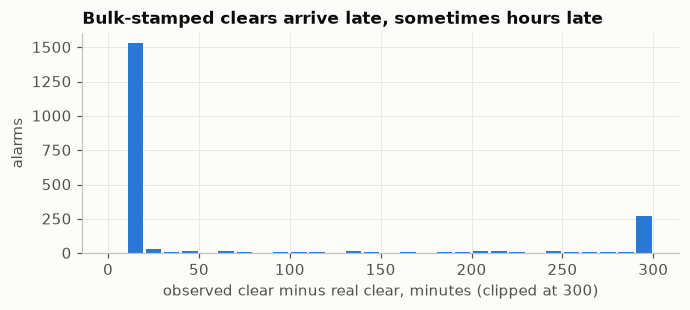

In [8]:
err = (a.clear_time - a.true_clear_time).dt.total_seconds() / 60
bulk = a.clear_is_bulk
print(f"Bulk-stamped clear times: {bulk.mean():.0%} of alarms; "
      f"median lag behind the real clear {err[bulk].median():.0f} min, 90th percentile {err[bulk].quantile(.9):.0f} min")
print(f"Missing clear times: {a.clear_time.isna().mean():.0%}")

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.hist(err[bulk].clip(upper=300), bins=np.arange(0, 305, 10), color=BLUE, rwidth=.85)
ax.set_xlabel("observed clear minus real clear, minutes (clipped at 300)")
ax.set_ylabel("alarms")
ax.set_title("Bulk-stamped clears arrive late, sometimes hours late")
plt.show()

43,239 candidate pairs; 66% of them are truly the same incident (the base rate)


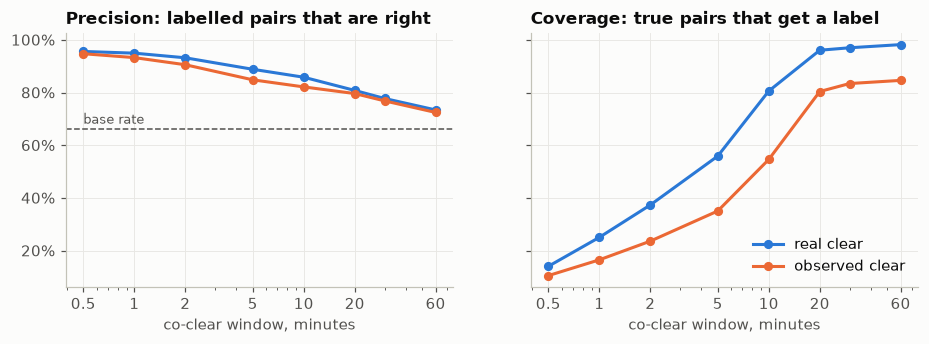

precision             ...           lift           
source     observed clear real clear  ... observed clear real clear
window_min                            ...                          
0.5                  0.95       0.96  ...           1.43       1.44
1.0                  0.93       0.95  ...           1.41       1.43
2.0                  0.91       0.93  ...           1.37       1.41
5.0                  0.85       0.89  ...           1.28       1.34
10.0                 0.82       0.86  ...           1.24       1.30
20.0                 0.80       0.81  ...           1.20       1.22
30.0                 0.77       0.78  ...           1.16       1.18
60.0                 0.73       0.73  ...           1.10       1.11

[8 rows x 6 columns]

In [9]:
# Candidate pairs: alarms on the same or directly linked sites whose onsets are within 15 minutes.
site_pairs = pd.concat([
    links[["a_site_id", "b_site_id"]],
    links.rename(columns={"a_site_id": "b_site_id", "b_site_id": "a_site_id"})[["a_site_id", "b_site_id"]],
    pd.DataFrame({"a_site_id": sites.site_id, "b_site_id": sites.site_id}),
]).drop_duplicates()
cols = ["alarm_id", "site_id", "onset_time", "clear_time", "true_clear_time", "incident_id"]
placed = a.dropna(subset=["site_id"])[cols]
p = (placed.merge(site_pairs, left_on="site_id", right_on="a_site_id")
           .merge(placed, left_on="b_site_id", right_on="site_id", suffixes=("_1", "_2")))
p = p[(p.alarm_id_1 < p.alarm_id_2) & ((p.onset_time_1 - p.onset_time_2).abs() <= pd.Timedelta("15min"))]
p["same"] = p.incident_id_1 == p.incident_id_2
base = p.same.mean()
print(f"{len(p):,} candidate pairs; {base:.0%} of them are truly the same incident (the base rate)")

rows = []
for source, c1, c2 in [("observed clear", "clear_time_1", "clear_time_2"), ("real clear", "true_clear_time_1", "true_clear_time_2")]:
    gap = (p[c1] - p[c2]).abs().dt.total_seconds() / 60
    for w in [.5, 1, 2, 5, 10, 20, 30, 60]:
        hit = gap <= w
        rows.append(dict(source=source, window_min=w, precision=p.same[hit].mean(),
                         coverage=hit[p.same].mean(), lift=p.same[hit].mean() / base))
coclear = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, metric, title in [(axes[0], "precision", "Precision: labelled pairs that are right"),
                          (axes[1], "coverage", "Coverage: true pairs that get a label")]:
    for source, colour in [("real clear", BLUE), ("observed clear", ORANGE)]:
        d = coclear[coclear.source == source]
        ax.plot(d.window_min, d[metric], color=colour, marker="o", ms=5, label=source)
    ax.set_xscale("log")
    ax.set_xticks([.5, 1, 2, 5, 10, 20, 60], ["0.5", "1", "2", "5", "10", "20", "60"])
    ax.set_xlabel("co-clear window, minutes")
    ax.set_title(title)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].axhline(base, color=MUTED, lw=1, ls="--")
axes[0].text(.5, base + .02, "base rate", color=MUTED, fontsize=8.5)
axes[1].legend(loc="lower right")
(ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "reports" / "figures" / "coclear_tradeoff.png", dpi=110, bbox_inches="tight")
plt.show()

coclear.pivot(index="window_min", columns="source", values=["precision", "coverage", "lift"]).round(2)

## 6 · Candidate label C: resolution codes

When a ticket closes, the crew records what fixed it (three tiers). Resolutions don't depend on clear times, so they can label pairs of
**tickets** that clear times can't. They are noisy, though, and they say what was fixed, not which tickets belong together.

In [10]:
kind_of_t3 = {v[2]: k for k, v in RESOLUTION.items()}
t["resolution_kind"] = t.res_tier3.map(kind_of_t3)
t["true_kind"] = t.incident_id.map(incidents.set_index("incident_id").kind)
print(f"Resolution matches the true cause on {(t.resolution_kind == t.true_kind).mean():.0%} of tickets")

# Ticket pairs: same region, opened within 30 minutes. Does "same resolution" mean "same incident"?
t["region"] = t.site_id.map(sites.set_index("site_id").region)
tr = t.dropna(subset=["region"])[["ticket_id", "region", "open_time", "res_tier3", "incident_id"]]
tp = tr.merge(tr, on="region", suffixes=("_1", "_2"))
tp = tp[(tp.ticket_id_1 < tp.ticket_id_2) & ((tp.open_time_1 - tp.open_time_2).abs() <= pd.Timedelta("30min"))]
tp["same_resolution"] = tp.res_tier3_1 == tp.res_tier3_2
tp["same_incident"] = tp.incident_id_1 == tp.incident_id_2
res_pairs = pd.crosstab(tp.same_resolution, tp.same_incident, normalize="index").round(2)
print(f"{len(tp):,} ticket pairs. Share that are truly the same incident, by whether the resolution matches:")
res_pairs

Resolution matches the true cause on 92% of tickets
7,057 ticket pairs. Share that are truly the same incident, by whether the resolution matches:


same_incident,False,True
same_resolution,,
False,0.66,0.34
True,0.04,0.96


## 7 · Summary

Every candidate label is wrong in a different way. That shapes the rest of the project:

In [11]:
best = coclear[(coclear.source == "observed clear")].set_index("window_min")
summary = pd.DataFrame([
    dict(label="Tickets", covers=f"{recall:.0%} of a ticketed incident's alarms",
         fails_by=f"one ticket per site; {t.is_repeat.mean():.0%} of tickets are repeats, "
                  f"{t.loc[t.is_repeat, 'marked_duplicate'].mean():.0%} of those marked",
         used_as="weak positive pairs inside one ticket"),
    dict(label="Clear time (5 min)", covers=f"{best.loc[5, 'coverage']:.0%} of true pairs",
         fails_by=f"{bulk.mean():.0%} bulk-stamped; precision {best.loc[5, 'precision']:.0%}, lift {best.loc[5, 'lift']:.1f}x",
         used_as="training label, tight window only"),
    dict(label="Resolution", covers="ticket pairs, no clear time needed",
         fails_by=f"same resolution: {res_pairs.loc[True, True]:.0%} same incident; "
                  f"but {res_pairs.loc[False, True]:.0%} of mismatched pairs are one incident too (noisy codes)",
         used_as="evaluation and ticket-level checks"),
    dict(label="No site", covers=f"{alarms.site_id.isna().mean():.0%} of alarms",
         fails_by="no topology, only a node alias", used_as="kept as placeless nodes, never dropped"),
]).set_index("label")
summary

,covers,fails_by,used_as
label,,,
Tickets,75% of a ticketed incident's alarms,"one ticket per site; 20% of tickets are repeats, 21% of those marked",weak positive pairs inside one ticket
Clear time (5 min),35% of true pairs,"6% bulk-stamped; precision 85%, lift 1.3x","training label, tight window only"
Resolution,"ticket pairs, no clear time needed",same resolution: 96% same incident; but 34% of mismatched pairs are one incident too (noisy codes),evaluation and ticket-level checks
No site,31% of alarms,"no topology, only a node alias","kept as placeless nodes, never dropped"


**Takeaways**

* No single signal is a label. Tickets are fragmented by design, clear times are partly fabricated, resolutions are noisy.
* A tight co-clear window gives a usable training signal; widening it buys coverage at the cost of precision and lift.
* Resolution codes are most useful for **evaluation**, because they're independent of the clear time the model learns from.
* Close to a third of the alarms have no site. Any method that needs topology must still decide what to do with them.

Next: [`02_model_and_clustering.ipynb`](02_model_and_clustering.ipynb) builds the alarm graph and the GNN that scores alarm pairs.